# 05 · Неопределённость и ошибки всех трёх классов

## tl;dr

Показаны ошибки normal, suspect и pathologic, интервалы по группам префиксов и концентрация патологических сегментов. CI условны на выполненных CV fits; разброс повторов не считается набором независимых исследований.

Исправленная процедура: mean group-balanced Macro-F1 **0.855**, recall suspect **70.5%**, recall pathologic **82.6%**. Это средние метрики трёх повторов, не точность финального full-data fit.


## Context & Methods
### Key Assumptions
Bootstrap ресэмплирует префиксы с кратностью, сохраняя исходные веса сегментов внутри выбранной группы. На каждом bootstrap считается средняя метрика трёх повторов. Это условная неопределённость на выполненных fits; не retraining bootstrap и не исправление человеческого post-review выбора постановки.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · интервалы и ошибки

In [5]:
from src.training.ctg_review_assessment import uci_assessment
if not (UCI/'conditional_intervals.csv').exists():uci_assessment()
intervals=pd.read_csv(UCI/'conditional_intervals.csv')
display(intervals[intervals.family=='selected_procedure'][['metric','estimate','ci_low','ci_high']].round(4))


,metric,estimate,ci_low,ci_high
42,macro_f1,0.8548,0.8197,0.8833
43,recall_normal,0.9713,0.9522,0.9850
44,recall_suspect,0.7050,0.6107,0.7844
45,recall_path,0.8260,0.7373,0.8966
46,log_loss,0.1805,0.1426,0.2199
47,ap_path,0.9248,0.8444,0.9732
48,auc_path,0.9934,0.9884,0.9971


## Results · качество и неопределённость

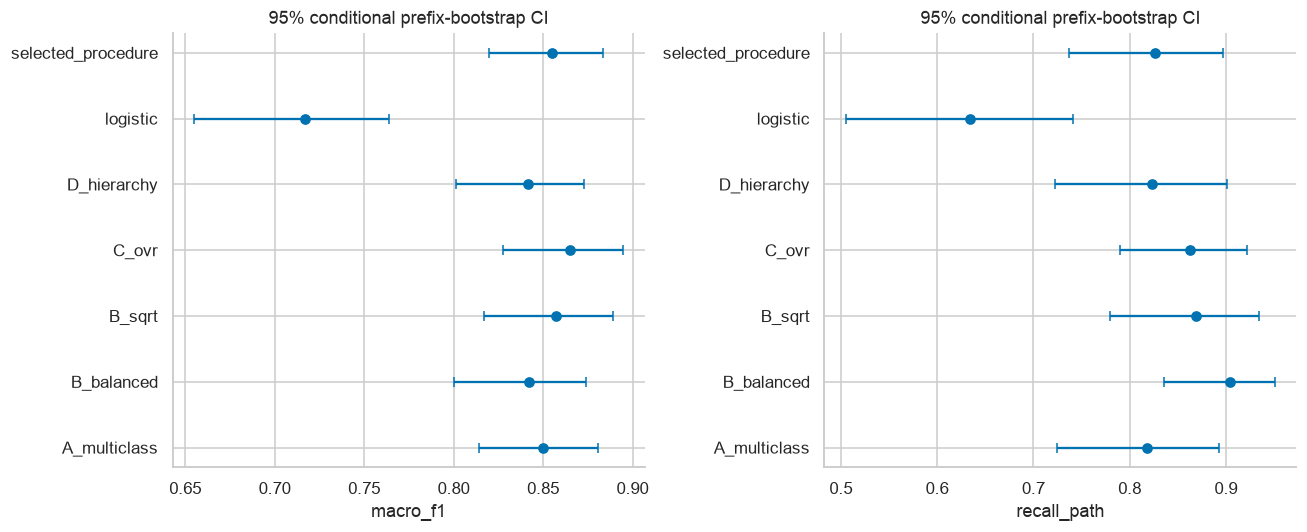

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,metric in zip(axes,['macro_f1','recall_path']):
    z=intervals[intervals.metric==metric].reset_index(drop=True)
    ax.errorbar(z.estimate,np.arange(len(z)),xerr=np.array([z.estimate-z.ci_low,z.ci_high-z.estimate]),fmt='o',capsize=3,color='#0072b2')
    ax.set(yticks=range(len(z)),yticklabels=z.family,xlabel=metric,title='95% conditional prefix-bootstrap CI')
fig.tight_layout();save_show('uci05_conditional_intervals.png')


### Подозрительные случаи и альтернативные CLASS-паттерны

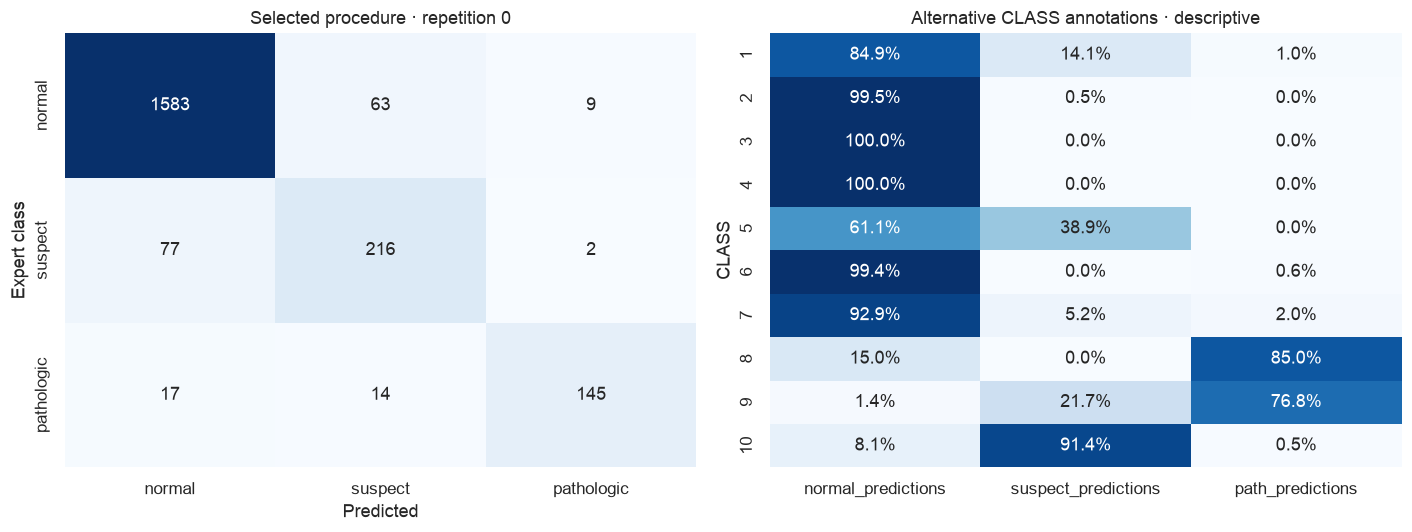

,repetition,CLASS,segments,proxy_groups,normal_predictions,suspect_predictions,path_predictions
0,0,1,384,85,326,54,4
1,0,2,579,124,576,3,0
2,0,3,53,27,53,0,0
3,0,4,81,23,81,0,0
4,0,5,72,24,44,28,0
5,0,6,332,66,330,0,2
6,0,7,252,61,234,13,5
7,0,8,107,18,16,0,91
8,0,9,69,19,1,15,53
9,0,10,197,32,16,180,1


recall  precision      ap  roc_auc
family             label                                    
A_multiclass       0      0.9725     0.9506  0.9944   0.9758
                   1      0.6866     0.7608  0.7938   0.9633
                   2      0.8184     0.9229  0.9225   0.9931
B_balanced         0      0.9259     0.9816  0.9942   0.9750
                   1      0.8490     0.6414  0.7716   0.9581
                   2      0.9039     0.7907  0.9220   0.9925
B_sqrt             0      0.9529     0.9702  0.9944   0.9760
                   1      0.7926     0.7061  0.7944   0.9608
                   2      0.8689     0.8596  0.9213   0.9927
C_ovr              0      0.9738     0.9537  0.9946   0.9770
                   1      0.7013     0.7967  0.8039   0.9634
                   2      0.8625     0.9116  0.9316   0.9941
D_hierarchy        0      0.9721     0.9511  0.9946   0.9766
                   1      0.6689     0.7561  0.7853   0.9630
                   2      0.8231     0.8881  0.9129   0.9936
logistic           0      0.9594     0.9242  0.9769   0.9427
                   1      0.4898     0.6452  0.5941   0.9257
                   2      0.6339     0.6736  0.7018   0.9340
selected_procedure 0      0.9713     0.9532  0.9944   0.9758
                   1      0.7050     0.7615  0.7934   0.9635
                   2      0.8260     0.9221  0.9248   0.9934

In [9]:
cm=pd.read_csv(UCI/'repeat_confusions.csv');z=cm[(cm.family=='selected_procedure')&(cm.repetition==0)]
matrix=z.pivot(index='actual',columns='predicted',values='segments').reindex(index=[0,1,2],columns=[0,1,2])
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',cbar=False,ax=axes[0],xticklabels=['normal','suspect','pathologic'],yticklabels=['normal','suspect','pathologic'])
axes[0].set(title='Selected procedure · repetition 0',xlabel='Predicted',ylabel='Expert class')
patterns=pd.read_csv(UCI/'CLASS_pattern_errors.csv');p=patterns[patterns.repetition==0].set_index('CLASS')
values=p[['normal_predictions','suspect_predictions','path_predictions']].div(p.segments,axis=0)
sns.heatmap(values,annot=True,fmt='.1%',cmap='Blues',cbar=False,ax=axes[1]);axes[1].set(title='Alternative CLASS annotations · descriptive')
fig.tight_layout();save_show('uci05_error_patterns.png')
display(patterns.round(4))
details=pd.read_csv(UCI/'per_class_metrics.csv')
display(details.groupby(['family','label'])[['recall','precision','ap','roc_auc']].mean().round(4))


## Takeaways

UCI используется как benchmark экспертных классов. Префикс — прокси независимого источника, не подтверждённый ID пациентки. Все данные ранее просмотрены: эта ревизия оценивает исправленную процедуру на повторной nested CV, без нового blind-test заявления. Полный разбор 23 замечаний — в [07](07_deep_audit_and_recommendations.ipynb).
